# Predicción del Tiempo Real de Entrega de Pedidos (Lead Time Logístico)

Dataset: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

Estructura del notebook: sigue la numeración de la consigna (secciones 1 a 9, ver `tarea.md`).

| Sección | Estado |
|---|---|
| 1. Contexto del negocio | hecho |
| 2. Objetivo principal | hecho |
| 3. Variable objetivo (y) | hecho |
| 4. Construcción del dataset (X) | hecho |
| 5. Procesamiento y limpieza | pendiente |
| 6. Estrategia de validación | pendiente |
| 7. Modelos | pendiente |
| 8. Métricas | pendiente |
| 9. Entregables | pendiente |

## 1. Contexto del Negocio

Para una plataforma de comercio electrónico como Olist, estimar con precisión el tiempo de entrega es clave para gestionar la experiencia del usuario y optimizar la logística. La plataforma ya calcula una fecha de entrega estimada con reglas predefinidas. Un modelo de Machine Learning permite estimar de forma continua el tiempo real de entrega, en días, desde el momento exacto de la compra.

## 2. Objetivo Principal

Desarrollar, evaluar y comparar modelos de regresión supervisados para predecir la variable continua `y`: el tiempo total de entrega, en días, desde la fecha de compra hasta la entrega efectiva en el domicilio del cliente.

## 3. Definición de la Variable Objetivo (y)

$$y = \frac{\texttt{order\_delivered\_customer\_date} - \texttt{order\_purchase\_timestamp}}{24\ \text{horas}}$$

Se filtran las órdenes no entregadas (`order_status != 'delivered'`) y las que no tienen fecha de entrega.

In [29]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA = Path("data")  # carpeta con los CSV de Olist

In [30]:
# tabla de pedidos, con las fechas leídas como fechas
orders = pd.read_csv(
    DATA / "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
    ],
)

print("Órdenes totales:", len(orders))
print(orders["order_status"].value_counts())

Órdenes totales: 99441
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [31]:
# nos quedamos con las órdenes entregadas y con fecha real de entrega
orders = orders[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].notna())
].copy()

# y en días (con decimales): total_seconds() / segundos de un día
orders["y"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 3600)

print("Órdenes entregadas:", len(orders))
orders["y"].describe()

Órdenes entregadas: 96470


count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: y, dtype: float64

In [32]:
# solo inspeccionamos los valores raros de y: se tratan en la sección 5
print("y negativos:", (orders["y"] < 0).sum())
print("y > 90 días:", (orders["y"] > 90).sum())
print("y > 120 días:", (orders["y"] > 120).sum())
print("\nPercentiles de y:")
print(orders["y"].quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(2))

y negativos: 0
y > 90 días: 77
y > 120 días: 43

Percentiles de y:
0.01     1.83
0.25     6.77
0.50    10.22
0.75    15.72
0.99    46.05
Name: y, dtype: float64


## 4. Construcción del Dataset de Entrenamiento (X)

Unificamos las tablas del dataset relacional para construir las variables predictoras a nivel de orden (`order_id`). Cada subsección (A a D) produce una tabla con una fila por orden, y al final se unen todas.

In [33]:
# carga del resto de las tablas
customers = pd.read_csv(DATA / "olist_customers_dataset.csv")
order_items = pd.read_csv(DATA / "olist_order_items_dataset.csv")
order_payments = pd.read_csv(DATA / "olist_order_payments_dataset.csv")
products = pd.read_csv(DATA / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA / "olist_sellers_dataset.csv")
geolocation = pd.read_csv(DATA / "olist_geolocation_dataset.csv")

# nos quedamos solo con los ítems de las órdenes que pasaron el filtro de la sección 3
order_items = order_items[order_items["order_id"].isin(orders["order_id"])].copy()
order_payments = order_payments[order_payments["order_id"].isin(orders["order_id"])].copy()

print("Ítems:", len(order_items), "| Pagos:", len(order_payments))

Ítems: 110189 | Pagos: 100748


### A. Variables Geográficas y Logísticas

- **Distancia (km):** Haversine entre las coordenadas del vendedor y del comprador.
- **Mismo estado:** 1 si `customer_state == seller_state`, 0 en caso contrario.

Antes de agregar `geolocation` descartamos las coordenadas que caen fuera de Brasil: en la primera versión la distancia máxima daba 8 678 km, más que cualquier distancia posible dentro del país (aprox. 4 400 km).

In [34]:
# coordenadas dentro de Brasil (caja aproximada)
geo = geolocation[
    geolocation["geolocation_lat"].between(-34, 6)
    & geolocation["geolocation_lng"].between(-74, -34)
]
print("Filas de geolocation fuera de Brasil descartadas:", len(geolocation) - len(geo))

# una fila por código postal: promedio de lat y lng
geo_agg = (
    geo.groupby("geolocation_zip_code_prefix")
    .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"))
    .reset_index()
)

# dos copias con nombres distintos: una para el comprador y otra para el vendedor
geo_cli = geo_agg.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "lat": "lat_cli", "lng": "lng_cli",
})
geo_ven = geo_agg.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "lat": "lat_ven", "lng": "lng_ven",
})

Filas de geolocation fuera de Brasil descartadas: 42


In [35]:
# destino: pedido + cliente + coordenadas del cliente
destino = (
    orders[["order_id", "customer_id"]]
    .merge(customers[["customer_id", "customer_zip_code_prefix", "customer_state"]],
           on="customer_id", how="inner")
    .merge(geo_cli, on="customer_zip_code_prefix", how="left")
)


def haversine_km(lat1, lng1, lat2, lng2):
    """Distancia en km entre dos puntos (latitud y longitud en grados)."""
    radio_tierra = 6371.0
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat = lat2 - lat1
    dlng = lng2 - lng1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng / 2) ** 2
    return 2 * radio_tierra * np.arcsin(np.sqrt(a))


# ítems con datos del vendedor y del comprador
items_geo = (
    order_items[["order_id", "order_item_id", "seller_id"]]
    .merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]],
           on="seller_id", how="left")
    .merge(geo_ven, on="seller_zip_code_prefix", how="left")
    .merge(destino[["order_id", "customer_state", "lat_cli", "lng_cli"]],
           on="order_id", how="inner")
)

items_geo["distancia_km"] = haversine_km(
    items_geo["lat_cli"], items_geo["lng_cli"], items_geo["lat_ven"], items_geo["lng_ven"]
)
items_geo["mismo_estado"] = (items_geo["customer_state"] == items_geo["seller_state"]).astype(int)

# una fila por orden
# mismo_estado = 1 solo si TODOS los ítems vienen del estado del comprador (min)
feat_geo = items_geo.groupby("order_id").agg(
    distancia_km=("distancia_km", "mean"),
    mismo_estado=("mismo_estado", "min"),
    customer_state=("customer_state", "first"),
    seller_state=("seller_state", "first"),
).reset_index()

print(feat_geo.shape)
feat_geo["distancia_km"].describe()

(96470, 5)


count    95993.000000
mean       600.414282
std        592.055775
min          0.000000
25%        187.747506
50%        433.839063
75%        797.530165
max       3399.190906
Name: distancia_km, dtype: float64

### B. Variables del Producto e Ítems

- **Volumen total:** (largo × alto × ancho) / 1000, en dm³.
- **Peso total:** suma de `product_weight_g` por orden.
- **Cantidad de ítems** (`count_items`).
- **Diversidad de vendedores:** vendedores distintos en el mismo pedido.

Se usa `sum(min_count=1)` para que una orden cuyos productos no tienen peso o dimensiones quede como `NaN` y no como 0.

In [36]:
# volumen de cada producto en dm3
products["volumen_dm3"] = (
    products["product_length_cm"]
    * products["product_height_cm"]
    * products["product_width_cm"]
) / 1000

items_prod = order_items[["order_id", "order_item_id", "product_id", "seller_id"]].merge(
    products[["product_id", "product_category_name", "product_weight_g", "volumen_dm3"]],
    on="product_id", how="left",
)

feat_prod = items_prod.groupby("order_id").agg(
    volumen_dm3=("volumen_dm3", lambda s: s.sum(min_count=1)),
    peso_g=("product_weight_g", lambda s: s.sum(min_count=1)),
    count_items=("order_item_id", "count"),
    n_vendedores=("seller_id", "nunique"),
    product_category_name=("product_category_name", "first"),  # categoría del primer ítem
).reset_index()

print(feat_prod.shape)
feat_prod.head()

(96470, 6)


,order_id,volumen_dm3,peso_g,count_items,n_vendedores,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,3.528,650.0,1,1,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,60.000,30000.0,1,1,pet_shop
2,000229ec398224ef6ca0657da4fc703e,14.157,3050.0,1,1,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,2.400,200.0,1,1,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,42.000,3750.0,1,1,ferramentas_jardim


### C. Variables Financieras

- **Precio total** de la orden: suma de `price`.
- **Valor total del flete:** suma de `freight_value`.
- **Ratio flete/precio:** `flete_total / precio_total`.
- **Cuotas de pago:** máximo de `payment_installments` por orden.

In [37]:
feat_items = order_items.groupby("order_id").agg(
    precio_total=("price", "sum"),
    flete_total=("freight_value", "sum"),
).reset_index()

feat_pagos = order_payments.groupby("order_id").agg(
    cuotas_max=("payment_installments", "max"),
).reset_index()

feat_fin = feat_items.merge(feat_pagos, on="order_id", how="left")

# replace(0, nan) evita dividir por cero si algún pedido tuviera precio 0
feat_fin["ratio_flete_precio"] = feat_fin["flete_total"] / feat_fin["precio_total"].replace(0, np.nan)

print(feat_fin.shape)
feat_fin.head()

(96470, 5)


,order_id,precio_total,flete_total,cuotas_max,ratio_flete_precio
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,2.0,0.225637
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,3.0,0.083076
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,5.0,0.089799
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,2.0,0.984604
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,3.0,0.090745


### D. Variables Temporales

Extraídas de `order_purchase_timestamp`: día de la semana (0 a 6), hora (0 a 23), mes (1 a 12) y binario de fin de semana.

In [38]:
ts = orders["order_purchase_timestamp"]

feat_temp = orders[["order_id"]].copy()
feat_temp["dia_semana"] = ts.dt.dayofweek          # 0 = lunes
feat_temp["hora"] = ts.dt.hour
feat_temp["mes"] = ts.dt.month
feat_temp["es_fin_de_semana"] = (ts.dt.dayofweek >= 5).astype(int)

feat_temp.head()

,order_id,dia_semana,hora,mes,es_fin_de_semana
0,e481f51cbdc54678b7cc49136f2d6af7,0,10,10,0
1,53cdb2fc8bc7dce0b6741e2150273451,1,20,7,0
2,47770eb9100c2d0c44946d9cf07ec65d,2,8,8,0
3,949d5b44dbf5de918fe9c16f97b45f8a,5,19,11,1
4,ad21c59c0840e6cb83a9ceb5573f8159,1,21,2,0


### Unión final
Se unen la variable objetivo y las cuatro tablas de variables. Se conservan `order_purchase_timestamp` (para la división temporal de la sección 6) y `order_estimated_delivery_date` (solo para la comparación de negocio de la sección 9; no es una variable predictora).

In [39]:
base = orders[["order_id", "order_purchase_timestamp", "order_estimated_delivery_date", "y"]]

df = (
    base
    .merge(feat_geo, on="order_id", how="inner")
    .merge(feat_prod, on="order_id", how="left")
    .merge(feat_fin, on="order_id", how="left")
    .merge(feat_temp, on="order_id", how="left")
)

print("Filas:", len(df), "| order_id únicos:", df["order_id"].nunique())
assert len(df) == df["order_id"].nunique(), "Hay órdenes duplicadas: revisar los joins"

print("\nValores faltantes por columna:")
print(df.isna().sum()[lambda s: s > 0])

Filas: 96470 | order_id únicos: 96470

Valores faltantes por columna:
distancia_km              477
volumen_dm3                16
peso_g                     16
product_category_name    1332
cuotas_max                  1
dtype: int64


In [40]:
# verificación de la distancia tras limpiar las coordenadas
print("Órdenes con distancia > 4500 km:", (df["distancia_km"] > 4500).sum())
print("Distancia máxima:", round(df["distancia_km"].max()), "km")

print(df.shape)
df.head()

Órdenes con distancia > 4500 km: 0
Distancia máxima: 3399 km
(96470, 21)


,order_id,order_purchase_timestamp,order_estimated_delivery_date,y,distancia_km,mismo_estado,customer_state,seller_state,volumen_dm3,peso_g,...,n_vendedores,product_category_name,precio_total,flete_total,cuotas_max,ratio_flete_precio,dia_semana,hora,mes,es_fin_de_semana
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-18,8.436574,18.576110,1,SP,SP,1.976,500.0,...,1,utilidades_domesticas,29.99,8.72,1.0,0.290764,0,10,10,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-13,13.782037,851.495069,0,BA,SP,4.693,400.0,...,1,perfumaria,118.70,22.76,1.0,0.191744,1,20,7,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-09-04,9.394213,514.410666,0,GO,SP,9.576,420.0,...,1,automotivo,159.90,19.22,3.0,0.120200,2,8,8,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-15,13.208750,1822.226336,0,RN,MG,6.000,450.0,...,1,pet_shop,45.00,27.20,1.0,0.604444,5,19,11,1
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-26,2.873877,29.676625,1,SP,SP,11.475,250.0,...,1,papelaria,19.90,8.72,1.0,0.438191,1,21,2,0


## 5. Requisitos de Procesamiento de Datos y Limpieza

Para evitar la fuga de datos, todo lo que se *aprende de los datos* (percentiles de recorte, medianas de imputación, medias y escalas, categorías del one-hot) debe calcularse **solo con el conjunto de entrenamiento**. Por eso, en esta sección **definimos** las transformaciones y en la sección 6, después de dividir por fecha, las **ajustamos** con `fit` sobre train.

La única limpieza que se aplica ahora a todos los datos es la de `y`, porque son reglas fijas (no se aprende nada de los datos).

### Tratamiento de Outliers

**Variable objetivo `y`:** se eliminan los valores negativos (entrega antes de la compra, imposible) y los tiempos extremos superiores a 120 días.

In [41]:
print("Órdenes antes de limpiar y:", len(df))
print("  y negativos:", (df["y"] < 0).sum())
print("  y > 120 días:", (df["y"] > 120).sum())

df = df[(df["y"] >= 0) & (df["y"] <= 120)].copy()

print("Órdenes después de limpiar y:", len(df))
df["y"].describe()

Órdenes antes de limpiar y: 96470
  y negativos: 0
  y > 120 días: 43
Órdenes después de limpiar y: 96427


count    96427.000000
mean        12.491389
std          8.992399
min          0.533414
25%          6.764716
50%         10.214225
75%         15.705503
max        118.969560
Name: y, dtype: float64

**Variables físicas y fletes:** se usan los percentiles 1 % y 99 % (winsorización): cada valor se recorta a esos límites, sin eliminar filas. El transformador calcula los límites en `fit` (solo con train) y los aplica en `transform`.

In [42]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin


class Winsorizador(BaseEstimator, TransformerMixin):
    """Recorta cada columna a los percentiles [p_bajo, p_alto] calculados en fit."""

    def __init__(self, p_bajo=1, p_alto=99):
        self.p_bajo = p_bajo
        self.p_alto = p_alto

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.limite_bajo_ = np.nanpercentile(X, self.p_bajo, axis=0)
        self.limite_alto_ = np.nanpercentile(X, self.p_alto, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.limite_bajo_, self.limite_alto_)  # los NaN se mantienen

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

In [43]:
# variables continuas con distribución muy sesgada (cola larga a la derecha)
vars_asimetricas = [
    "distancia_km", "volumen_dm3", "peso_g",
    "precio_total", "flete_total", "ratio_flete_precio",
]

# solo para observar: los percentiles que se usarán como límites
df[vars_asimetricas].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
distancia_km,95950.0,600.13,591.79,0.00,5.75,433.72,2482.91,3399.19
volumen_dm3,96411.0,17.33,30.14,0.17,0.35,7.25,135.59,1476.00
peso_g,96411.0,2386.51,4769.67,0.00,100.00,750.00,22350.00,184400.00
precio_total,96427.0,136.98,208.92,0.85,11.99,86.50,990.00,13440.00
flete_total,96427.0,22.78,21.56,0.00,7.39,17.17,104.24,1794.96
ratio_flete_precio,96427.0,0.31,0.31,0.00,0.03,0.22,1.46,21.45


### Ingeniería de Variables y Codificación

Se aplica **One-Hot Encoding** a `customer_state`, `seller_state` y `product_category_name`. Esta última tiene alta cardinalidad (unas 70 categorías), por eso las categorías con menos de 100 pedidos se agrupan en una sola columna "infrecuente", para no crear decenas de columnas casi vacías. Los valores faltantes de categoría se rellenan con `"desconocido"`.

In [44]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

vars_categoricas = ["customer_state", "seller_state", "product_category_name"]

pipe_categoricas = Pipeline([
    ("imputar", SimpleImputer(strategy="constant", fill_value="desconocido")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",  # categorías nuevas en test no rompen el modelo
        min_frequency=100,                     # agrupa las categorías raras
        sparse_output=False,
    )),
])

### Escalado

- **Variables sesgadas:** winsorización → imputación con la mediana → `log(1 + x)` → `RobustScaler`. El logaritmo comprime la cola larga y `RobustScaler` (mediana y rango intercuartílico) es poco sensible a los outliers.
- **Resto de las numéricas:** winsorización → imputación con la mediana → `RobustScaler`.
- **Binarias** (`mismo_estado`, `es_fin_de_semana`): pasan sin cambios.

Todo se reúne en un único `preprocesador` (`ColumnTransformer`), donde cada grupo de columnas recibe su propio tratamiento.

In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, RobustScaler

vars_numericas = ["count_items", "n_vendedores", "cuotas_max", "dia_semana", "hora", "mes"]
vars_binarias = ["mismo_estado", "es_fin_de_semana"]

pipe_asimetricas = Pipeline([
    ("recortar", Winsorizador(p_bajo=1, p_alto=99)),
    ("imputar", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("escalar", RobustScaler()),
])

pipe_numericas = Pipeline([
    ("recortar", Winsorizador(p_bajo=1, p_alto=99)),
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", RobustScaler()),
])

preprocesador = ColumnTransformer([
    ("asimetricas", pipe_asimetricas, vars_asimetricas),
    ("numericas", pipe_numericas, vars_numericas),
    ("binarias", "passthrough", vars_binarias),
    ("categoricas", pipe_categoricas, vars_categoricas),
])

columnas_X = vars_asimetricas + vars_numericas + vars_binarias + vars_categoricas
print("Variables predictoras:", len(columnas_X))
preprocesador

Variables predictoras: 17


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('asimetricas', ...), ('numericas', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` a

### Conclusiones de la sección 5

- **Outliers en `y`:** no hay valores negativos y se eliminaron 43 órdenes con `y` > 120 días (0,04 % del total). Quedaron 96 427 órdenes. Se eligió 120 días y no 90 para conservar las 34 órdenes entre 90 y 120 días, que son lentas pero plausibles.
- **Distribución de `y`:** tiene sesgo a la derecha (media 12,5 días, mediana 10,2 días, percentil 99 de 46 días). Los pocos pedidos muy lentos influirán sobre todo en el RMSE.
- **Outliers en variables físicas y fletes:** las variables tienen colas muy largas. Por ejemplo, el percentil 99 de `peso_g` es 22 350 g frente a un máximo de 184 400 g, el de `precio_total` es 990 frente a 13 440, y el de `ratio_flete_precio` es 1,46 frente a 21,45. Se aplica winsorización con los percentiles 1 % y 99 %, sin eliminar filas.
- **Distancia:** tras descartar las coordenadas fuera de Brasil, la distancia máxima es de 3 399 km (antes 8 678 km), por lo que el problema de coordenadas erróneas quedó resuelto.
- **Valores faltantes:** `distancia_km` tiene 477 (0,49 %), `volumen_dm3` y `peso_g` 16 cada una, `cuotas_max` 1 y `product_category_name` 1 332 (1,4 %). Las numéricas se imputan con la mediana (calculada solo en train) y la categoría con `"desconocido"`.
- **Codificación y escalado:** One-Hot en `customer_state`, `seller_state` y `product_category_name` (`min_frequency=100`), y `log(1 + x)` más `RobustScaler` en las variables sesgadas.
- **Decisión de diseño:** las transformaciones se definen en esta sección y se ajustan solo con train en la sección 6, para evitar la fuga de datos.

### Выводы к разделу 5

- **Выбросы в `y`:** отрицательных значений нет, удалено 43 заказа с `y` > 120 дней (0,04 % от всех). Осталось 96 427 заказов. Порог 120 дней выбран вместо 90, чтобы сохранить 34 заказа с доставкой от 90 до 120 дней: они медленные, но правдоподобные.
- **Распределение `y`:** скошено вправо (среднее 12,5 дня, медиана 10,2, 99-й перцентиль 46 дней). Редкие очень долгие доставки сильнее всего влияют на RMSE.
- **Выбросы в физических признаках и flete:** у признаков очень длинные правые хвосты. Например, 99-й перцентиль `peso_g` равен 22 350 г при максимуме 184 400 г, `precio_total` 990 при максимуме 13 440, `ratio_flete_precio` 1,46 при максимуме 21,45. Применяется винзоризация по перцентилям 1 % и 99 % без удаления строк.
- **Расстояние:** после отсечения координат вне Бразилии максимум 3 399 км (раньше 8 678 км), проблема ошибочных координат решена.
- **Пропуски:** `distancia_km` — 477 (0,49 %), `volumen_dm3` и `peso_g` — по 16, `cuotas_max` — 1, `product_category_name` — 1 332 (1,4 %). Числовые заполняются медианой (считается только по train), категория значением `"desconocido"`.
- **Кодирование и масштабирование:** One-Hot для `customer_state`, `seller_state`, `product_category_name` (`min_frequency=100`), а для скошенных признаков `log(1 + x)` и `RobustScaler`.
- **Проектное решение:** преобразования описываются в этом разделе, а обучаются только на train в разделе 6, чтобы не было утечки данных.


## 6. Estrategia de Validación del Modelo

**División temporal (time-based split):** no se usa `train_test_split` aleatorio, porque mezclaría datos del futuro con datos del pasado y produciría una evaluación demasiado optimista.

- **Entrenamiento:** pedidos de octubre de 2016 a mayo de 2018.
- **Prueba:** pedidos de junio de 2018 a agosto de 2018.

El criterio es la fecha de compra (`order_purchase_timestamp`). Después de dividir, el preprocesador se ajusta (`fit`) solo con train y sobre test se aplica únicamente `transform`.

In [46]:
fecha = df["order_purchase_timestamp"]

mask_train = (fecha >= "2016-10-01") & (fecha < "2018-06-01")
mask_test = (fecha >= "2018-06-01") & (fecha < "2018-09-01")

df_train = df[mask_train].copy()
df_test = df[mask_test].copy()

print(f"Train: {len(df_train)} órdenes ({fecha[mask_train].min().date()} a {fecha[mask_train].max().date()})")
print(f"Test:  {len(df_test)} órdenes ({fecha[mask_test].min().date()} a {fecha[mask_test].max().date()})")
print("Fuera de ambos períodos (descartadas):", len(df) - len(df_train) - len(df_test))
print(f"Proporción train/test: {len(df_train)/(len(df_train)+len(df_test)):.1%} / {len(df_test)/(len(df_train)+len(df_test)):.1%}")

# el test debe ser posterior al train
assert fecha[mask_train].max() < fecha[mask_test].min()

Train: 77824 órdenes (2016-10-03 a 2018-05-31)
Test:  18602 órdenes (2018-06-01 a 2018-08-29)
Fuera de ambos períodos (descartadas): 1
Proporción train/test: 80.7% / 19.3%


In [47]:
X_train, y_train = df_train[columnas_X], df_train["y"]
X_test, y_test = df_test[columnas_X], df_test["y"]

# fit SOLO con train; en test solo transform
X_train_p = preprocesador.fit_transform(X_train)
X_test_p = preprocesador.transform(X_test)

nombres_columnas = preprocesador.get_feature_names_out()

print("X_train procesado:", X_train_p.shape)
print("X_test procesado: ", X_test_p.shape)
print("NaN en train:", int(np.isnan(X_train_p).sum()), "| NaN en test:", int(np.isnan(X_test_p).sum()))
print("\nPrimeras columnas:", list(nombres_columnas[:8]))

X_train procesado: (77824, 104)
X_test procesado:  (18602, 104)
NaN en train: 0 | NaN en test: 0

Primeras columnas: ['asimetricas__distancia_km', 'asimetricas__volumen_dm3', 'asimetricas__peso_g', 'asimetricas__precio_total', 'asimetricas__flete_total', 'asimetricas__ratio_flete_precio', 'numericas__count_items', 'numericas__n_vendedores']


### Conclusiones de la sección 6

- **División temporal:** el conjunto de entrenamiento tiene 77 824 órdenes (del 03/10/2016 al 31/05/2018) y el de prueba 18 602 órdenes (del 01/06/2018 al 29/08/2018). La proporción es 80,7 % / 19,3 %, en línea con el 80 % aproximado que indica la consigna.
- **Órdenes descartadas:** 1 orden quedó fuera de ambos períodos.
- **Sin fuga de datos:** el test es posterior al train (verificado con `assert`) y el preprocesador se ajustó únicamente con train.
- **Dimensión tras el preprocesamiento:** 104 columnas, es decir, 14 variables numéricas y binarias más 90 columnas generadas por el One-Hot. No quedan valores faltantes ni en train ni en test.

### Выводы к разделу 6

- **Разбиение по времени:** в обучающей выборке 77 824 заказа (с 03.10.2016 по 31.05.2018), в тестовой 18 602 (с 01.06.2018 по 29.08.2018). Соотношение 80,7 % к 19,3 % совпадает с примерно 80 % из задания.
- **Отброшенные заказы:** 1 заказ не попал ни в один из периодов.
- **Нет утечки данных:** тест позже train (проверено через `assert`), а препроцессор обучен только на train.
- **Размерность после обработки:** 104 столбца, то есть 14 числовых и бинарных плюс 90 столбцов от One-Hot. Пропусков нет ни в train, ни в test.

## 7. Modelos a Implementar y Comparar

Se entrenan tres modelos de distinta complejidad, más una referencia mínima para poder interpretar los resultados:

| Modelo | Tipo | Idea |
|---|---|---|
| Referencia (media de train) | no es un modelo real | predice siempre el tiempo de entrega promedio del entrenamiento; sirve para saber cuánto mejora un modelo real |
| **Ridge** | baseline lineal | regresión lineal con penalización L2 sobre los coeficientes, que reduce el sobreajuste |
| **Random Forest Regressor** | árboles | promedia 200 árboles de decisión entrenados con muestras distintas; captura relaciones no lineales |
| **LightGBM Regressor** | boosting | construye árboles en secuencia, cada uno corrigiendo los errores del anterior |

**Hiperparámetros principales:** en Random Forest, `min_samples_leaf=5` evita hojas con muy pocos pedidos (menos sobreajuste); en LightGBM, `learning_rate=0.05` con `n_estimators=500` entrena de forma gradual, y `subsample` y `colsample_bytree` usan el 80 % de las filas y de las columnas en cada árbol. Todos usan `random_state=42` para que los resultados se puedan reproducir.

In [48]:
import time

from lightgbm import LGBMRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

modelos = {
    "Referencia (media de train)": DummyRegressor(strategy="mean"),
    "Ridge (baseline)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=500, learning_rate=0.05, num_leaves=63,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbose=-1,
    ),
}

### Entrenamiento

Cada modelo se entrena con los datos de entrenamiento ya preprocesados (`X_train_p`) y se guardan sus predicciones sobre train y sobre test. Las predicciones de train servirán para detectar sobreajuste.

In [49]:
predicciones_train = {}
predicciones_test = {}

for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    modelo.fit(X_train_p, y_train)
    predicciones_train[nombre] = modelo.predict(X_train_p)
    predicciones_test[nombre] = modelo.predict(X_test_p)
    print(f"{nombre:30s} entrenado en {time.perf_counter() - inicio:6.1f} s")

Referencia (media de train)    entrenado en    0.0 s
Ridge (baseline)               entrenado en    0.0 s
Random Forest                  entrenado en    9.1 s
LightGBM                       entrenado en    6.4 s


### Conclusiones de la sección 7

- **Modelos entrenados:** referencia (media), Ridge, Random Forest y LightGBM, todos sobre las mismas 104 columnas preprocesadas y las mismas 77 824 órdenes de entrenamiento.
- **Tiempos de entrenamiento:** la referencia y Ridge tardan menos de 0,1 s, LightGBM 6,2 s y Random Forest 9,0 s. El modelo más costoso fue Random Forest (200 árboles), aunque el costo es bajo en términos absolutos: los tres modelos se entrenan en pocos segundos.
- **Reproducibilidad:** todos los modelos con componente aleatorio usan `random_state=42`.

### Выводы к разделу 7

- **Обученные модели:** референс (среднее), Ridge, Random Forest и LightGBM, все на одних и тех же 104 преобразованных столбцах и 77 824 обучающих заказах.
- **Время обучения:** референс и Ridge менее 0,1 с, LightGBM 6,3 с, Random Forest 9,3 с. Самой затратной оказалась Random Forest (200 деревьев), но в абсолютных числах затраты малы: все модели обучаются за несколько секунд.
- **Воспроизводимость:** во всех моделях со случайной составляющей стоит `random_state=42`.

## 8. Métricas de Evaluación Obligatorias

Se evalúa el desempeño sobre el conjunto de prueba (junio a agosto de 2018) con cuatro métricas. En todas, $y_i$ es el tiempo real de entrega, $\hat{y}_i$ el predicho y $n$ la cantidad de órdenes de prueba.

- **MAE (Error Absoluto Medio):** error promedio en días. Es la más fácil de interpretar.

$$MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i \right|$$

- **RMSE (Raíz del Error Cuadrático Medio):** también está en días, pero al elevar al cuadrado penaliza más los errores grandes. Si es mucho mayor que el MAE, hay pocos pedidos con errores muy grandes.

$$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2}$$

- **R² (Coeficiente de Determinación):** proporción de la variabilidad de `y` que explica el modelo. 1 es perfecto, 0 equivale a predecir siempre el promedio y un valor negativo es peor que el promedio.

$$R^2 = 1 - \frac{\sum_{i}(y_i - \hat{y}_i)^2}{\sum_{i}(y_i - \bar{y})^2}$$

- **MAPE (Error Porcentual Absoluto Medio):** error relativo, en porcentaje. Se agranda cuando el valor real es pequeño (entregas muy rápidas).

$$MAPE = \frac{100\%}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right|$$

In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)


def evaluar(y_real, y_pred):
    """Devuelve las 4 métricas obligatorias."""
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_real, y_pred) * 100,
    }


# métricas sobre el conjunto de prueba, una fila por modelo
resultados = pd.DataFrame(
    {nombre: evaluar(y_test, pred) for nombre, pred in predicciones_test.items()}
).T

# MAE en train, para detectar sobreajuste (comparar con el MAE en test)
resultados["MAE_train"] = [
    mean_absolute_error(y_train, predicciones_train[nombre]) for nombre in resultados.index
]

resultados.round(3).sort_values("MAE")

,MAE,RMSE,R2,MAPE (%),MAE_train
LightGBM,4.298,5.680,0.022,68.595,4.400
Random Forest,4.309,5.679,0.023,69.239,3.391
Ridge (baseline),5.562,6.827,-0.412,90.847,5.374
Referencia (media de train),6.389,7.480,-0.695,134.094,6.643


In [51]:
# mejor modelo según MAE (sin contar la referencia)
mejor_modelo = resultados.drop(index="Referencia (media de train)")["MAE"].idxmin()
print("Mejor modelo:", mejor_modelo)

Mejor modelo: LightGBM


In [52]:
# comparación de la distribución de y entre train y test
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2)

,train,test
count,77824.00,18602.00
mean,13.41,8.63
std,9.37,5.75
min,0.53,0.86
25%,7.21,5.10
50%,11.18,7.35
75%,16.95,10.67
max,118.97,78.96


In [53]:
# tiempo medio de entrega por mes de compra
(
    df.groupby(df["order_purchase_timestamp"].dt.to_period("M"))["y"]
    .agg(["count", "mean", "std"])
    .round(2)
)

,count,mean,std
order_purchase_timestamp,,,
2016-09,1,54.81,NaN
2016-10,265,19.60,12.11
2016-12,1,4.69,NaN
2017-01,750,12.65,9.98
2017-02,1650,12.88,8.35
2017-03,2535,12.19,8.48
2017-04,2296,14.48,8.26
2017-05,3542,11.21,6.89
2017-06,3133,11.92,7.48


In [54]:
print("Última fecha de entrega registrada:", orders["order_delivered_customer_date"].max())
print("Última fecha de compra en el dataset:", orders["order_purchase_timestamp"].max())

Última fecha de entrega registrada: 2018-10-17 13:22:46
Última fecha de compra en el dataset: 2018-08-29 15:00:37


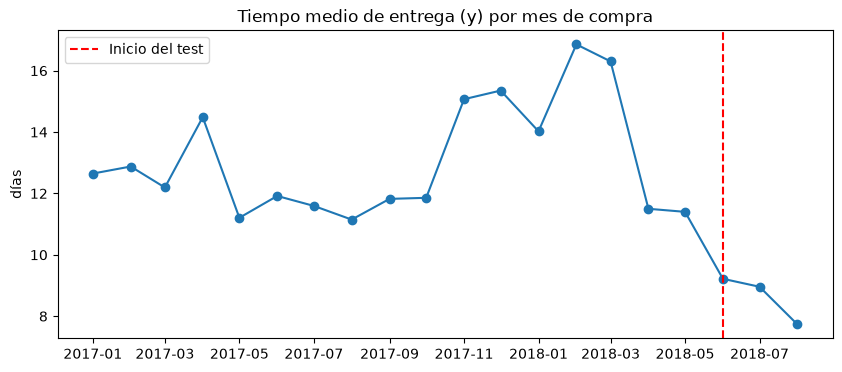

In [55]:
import matplotlib.pyplot as plt

mensual = df.groupby(df["order_purchase_timestamp"].dt.to_period("M"))["y"].mean()
mensual = mensual[mensual.index >= "2017-01"]  # se omiten los meses de 2016 con muy pocas órdenes
mensual.index = mensual.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensual.index, mensual.values, marker="o")
ax.axvline(pd.Timestamp("2018-06-01"), color="red", linestyle="--", label="Inicio del test")
ax.set_title("Tiempo medio de entrega (y) por mes de compra")
ax.set_ylabel("días")
ax.legend()
plt.savefig("../reports/figures/lead_time_media_mensual.png", bbox_inches="tight")
plt.show()

### Conclusiones de la sección 8

- **Mejor modelo:** LightGBM, con MAE = 4,30 días, RMSE = 5,68 días, R² = 0,022 y MAPE = 68,6 %. Random Forest queda prácticamente empatado (MAE = 4,31, RMSE = 5,68, R² = 0,023), así que no hay una diferencia relevante entre ambos. Se elige LightGBM por tener el MAE más bajo y no mostrar sobreajuste.
- **Comparación con la referencia:** la referencia (predecir siempre el promedio de train) tiene MAE = 6,39 y R² = −0,695. LightGBM reduce el MAE en un 32,7 %.
- **Baseline vs. modelos más complejos:** Ridge obtuvo MAE = 5,56 (R² = −0,41), frente a 4,30 y 4,31 de los modelos de árboles, que reducen el MAE en un 22,7 % respecto del baseline lineal. La relación entre las variables y el tiempo de entrega no es lineal. Ridge tiene un MAE similar en train y test (5,37 y 5,56), lo que sugiere subajuste: el modelo lineal es demasiado simple.
- **Sobreajuste:** Random Forest tiene MAE de 3,39 en train y 4,31 en test (un 27 % más), señal de que memoriza parte del entrenamiento. LightGBM tiene 4,40 en train y 4,30 en test, es decir, no hay sobreajuste.
- **RMSE vs. MAE:** el RMSE (5,68) supera al MAE (4,30) en 1,38 días. La diferencia es moderada: hay pedidos con errores grandes, probablemente entregas muy demoradas, pero no dominan el resultado.
- **MAPE:** el 68,6 % es alto porque las entregas muy rápidas (menos de 2 días) tienen un denominador pequeño, y un error de pocos días representa un porcentaje enorme. Debe leerse junto con el MAE.
- **Limitación principal (R² bajo):** con R² = 0,022, los modelos explican solo cerca del 2 % de la variabilidad de `y` en el período de prueba. Las variables disponibles al momento de la compra permiten reducir el error promedio, pero no predecir bien qué pedidos se demorarán más. Faltan factores como el clima, las huelgas, el tiempo de preparación del vendedor o el estado del transportista.
- **Cambio de distribución entre train y test:** el tiempo medio de entrega pasó de 13,41 días en train a 8,63 días en test (una diferencia de 4,78 días), y la desviación estándar bajó de 9,37 a 5,75 días. El detalle mensual muestra que el tiempo medio fue estable en 2017 (11-12 días), subió entre noviembre de 2017 y marzo de 2018 (14-17 días; en noviembre de 2017 los pedidos aumentaron de 4 478 a 7 283, probablemente por Black Friday), volvió a ~11,5 días en abril-mayo de 2018 y cayó a 9,2, 9,0 y 7,7 días en junio, julio y agosto de 2018, los valores más bajos de toda la serie. Esto explica el R² = −0,695 de la referencia: su error cuadrático medio es la varianza de test más el sesgo al cuadrado (5,75² + 4,78² ≈ 7,48²). Como la variabilidad de test es menor, el R² de los modelos (0,022) se calcula sobre una vara más exigente. Además, los meses 6 a 8 aparecen en train solo en 2017 (≈ 11,5 días), por lo que es probable que los modelos sobreestimen el tiempo de entrega en test; esto se verificará en la sección 9 con el sesgo de los errores. Una posible causa adicional de los valores bajos de 2018 es que el dataset solo incluye pedidos ya entregados, de modo que los pedidos más lentos de los últimos meses podrían faltar.


### Выводы к разделу 8

- **Лучшая модель:** LightGBM: MAE = 4,30 дня, RMSE = 5,68 дня, R² = 0,022, MAPE = 68,6 %. Random Forest практически не отличается (MAE = 4,31, RMSE = 5,68, R² = 0,023), существенной разницы между ними нет. LightGBM выбран за наименьший MAE и отсутствие переобучения.
- **Сравнение с референсом:** референс (всегда среднее по train) даёт MAE = 6,39 и R² = −0,695. LightGBM снижает MAE на 32,7 %.
- **Baseline и сложные модели:** Ridge — MAE = 5,56 (R² = −0,41) против 4,30 и 4,31 у деревьев, то есть деревья снижают MAE на 22,7 % относительно линейного baseline. Связь признаков со временем доставки нелинейная. У Ridge MAE на train и test близки (5,37 и 5,56): модель недообучена, она слишком простая.
- **Переобучение:** у Random Forest MAE на train 3,39, на test 4,31 (на 27 % выше), модель частично запоминает обучающую выборку. У LightGBM 4,40 и 4,30, переобучения нет.
- **RMSE и MAE:** RMSE (5,68) больше MAE (4,30) на 1,38 дня. Разница умеренная: есть заказы с большими ошибками, вероятно очень долгие доставки, но они не определяют результат.
- **MAPE:** 68,6 % — много, потому что у очень быстрых доставок (меньше 2 дней) знаменатель мал, и ошибка в пару дней превращается в огромный процент. Читать MAPE нужно вместе с MAE.
- **Главное ограничение (низкий R²):** при R² = 0,022 модели объясняют только около 2 % разброса `y` на тесте. Признаки, известные в момент покупки, помогают уменьшить среднюю ошибку, но плохо предсказывают, какие заказы задержатся. Не хватает погоды, забастовок, времени подготовки заказа продавцом и состояния перевозчика.
- **Сдвиг распределения между train и test:** среднее время доставки снизилось с 13,41 дня в train до 8,63 в test (разница 4,78 дня), стандартное отклонение — с 9,37 до 5,75. По месяцам видно: в 2017 году значение было стабильным (11–12 дней), с ноября 2017 по март 2018 выросло (14–17 дней; в ноябре 2017 число заказов выросло с 4 478 до 7 283, вероятно из-за Black Friday), в апреле – мае 2018 вернулось к ~11,5 дня и упало до 9,2, 9,0 и 7,7 дня в июне, июле и августе 2018, то есть до самых низких значений за весь период. Это объясняет R² референса (−0,695): его среднеквадратичная ошибка равна дисперсии теста плюс квадрат смещения (5,75² + 4,78² ≈ 7,48²). Поскольку разброс в тесте меньше, R² моделей (0,022) считается по более строгой шкале. Кроме того, месяцы 6–8 есть в train только за 2017 год (≈ 11,5 дня), поэтому модели, вероятно, завышают срок доставки на тесте; проверим это в разделе 9 по смещению ошибок. Ещё одна возможная причина низких значений в 2018 году: датасет содержит только уже доставленные заказы, поэтому самые медленные заказы последних месяцев могут отсутствовать.


## 9. Entregables Esperados

1. **Código en Jupyter Notebook:** limpio, documentado y reproducible. Este notebook sigue la numeración de la consigna y todas las celdas se pueden ejecutar de arriba hacia abajo (Restart & Run All) con `random_state=42` fijo en los modelos.
2. **Gráfico de análisis de residuos** del mejor modelo.
3. **Importancia de características:** los 10 factores principales.
4. **Conclusión de negocio:** comparación entre el tiempo predicho por el modelo y la estimación estática de la plataforma (`order_estimated_delivery_date`).

### 2. Gráfico de Análisis de Residuos

El **residuo** es la diferencia entre el valor real y el predicho: $y - \hat{y}$. Un residuo positivo significa que el pedido tardó *más* de lo predicho, y uno negativo, que tardó *menos* (el modelo lo sobreestimó).

Qué se busca en los gráficos:
- **Histograma:** una distribución centrada en 0 (sin sesgo) y sin colas muy pesadas.
- **Residuos vs. valor predicho:** una nube sin patrón. Si los residuos crecen o forman una curva, el modelo falla de forma sistemática en algún rango.

Modelo: LightGBM
Residuo medio (sesgo):  -2.59 días
Residuo mediano:        -3.05 días
Desvío estándar:        5.06 días
Pedidos sobreestimados (residuo < 0): 80.6%


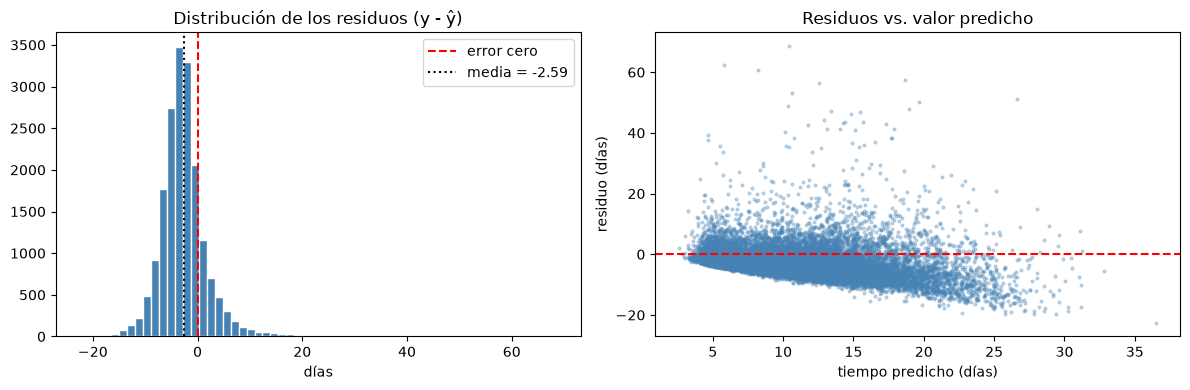

In [56]:
import matplotlib.pyplot as plt

modelo_final = modelos[mejor_modelo]
pred_test = predicciones_test[mejor_modelo]

# residuo = real - predicho (positivo: el pedido tardó MÁS de lo predicho)
residuos = y_test - pred_test

print(f"Modelo: {mejor_modelo}")
print(f"Residuo medio (sesgo):  {residuos.mean():.2f} días")
print(f"Residuo mediano:        {residuos.median():.2f} días")
print(f"Desvío estándar:        {residuos.std():.2f} días")
print(f"Pedidos sobreestimados (residuo < 0): {(residuos < 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(residuos, bins=60, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--", label="error cero")
axes[0].axvline(residuos.mean(), color="black", linestyle=":", label=f"media = {residuos.mean():.2f}")
axes[0].set_title("Distribución de los residuos (y - ŷ)")
axes[0].set_xlabel("días")
axes[0].legend()

axes[1].scatter(pred_test, residuos, s=4, alpha=0.3, color="steelblue")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuos vs. valor predicho")
axes[1].set_xlabel("tiempo predicho (días)")
axes[1].set_ylabel("residuo (días)")

plt.tight_layout()
plt.savefig("../reports/figures/lead_time_residuos.png", bbox_inches="tight")
plt.show()

### 3. Importancia de Características

Se usa la importancia por **ganancia** (*gain*) del mejor modelo: mide cuánto reduce el error cada variable cada vez que un árbol la usa para dividir los datos. Como el One-Hot convierte cada categoría en una columna, se suman las columnas de una misma variable original (por ejemplo, todas las de `customer_state`), para que el ranking sea por variable y no por columna.

mismo_estado             17.18
customer_state           16.52
distancia_km             16.06
mes                      10.45
flete_total               6.31
volumen_dm3               5.23
product_category_name     5.13
peso_g                    4.74
precio_total              4.41
ratio_flete_precio        4.11
dtype: float64


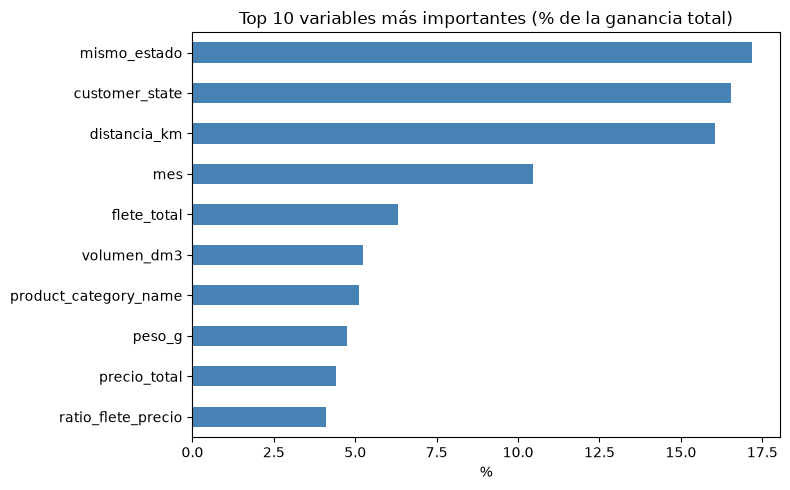

In [57]:
# importancia por ganancia: cuánto reduce el error cada variable al usarse en los árboles
if hasattr(modelo_final, "booster_"):          # LightGBM
    valores = modelo_final.booster_.feature_importance(importance_type="gain")
else:                                          # Random Forest
    valores = modelo_final.feature_importances_

importancia = pd.Series(valores, index=nombres_columnas)


def variable_original(nombre):
    """Agrupa las columnas del One-Hot en la variable categórica de origen."""
    sin_prefijo = nombre.split("__", 1)[1]
    for var in vars_categoricas:
        if sin_prefijo.startswith(var):
            return var
    return sin_prefijo


importancia_var = importancia.groupby(variable_original).sum()
importancia_pct = (importancia_var / importancia_var.sum() * 100).sort_values(ascending=False)

top10 = importancia_pct.head(10)
print(top10.round(2))

ax = top10[::-1].plot.barh(figsize=(8, 5), color="steelblue")
ax.set_title("Top 10 variables más importantes (% de la ganancia total)")
ax.set_xlabel("%")
plt.tight_layout()
plt.savefig("../reports/figures/lead_time_importancias.png", bbox_inches="tight")
plt.show()

### 4. Conclusión de Negocio: modelo vs. estimación estática de Olist

La plataforma muestra al cliente una fecha estimada fija (`order_estimated_delivery_date`). Se compara, sobre el conjunto de prueba, esa estimación con la predicción del mejor modelo, usando las mismas métricas. Ambas se miden en días desde la compra.

In [58]:
# estimación estática de Olist, en días desde la compra
estimacion_olist = (
    df_test["order_estimated_delivery_date"] - df_test["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 3600)

comparacion = pd.DataFrame({
    "Estimación Olist": evaluar(y_test, estimacion_olist),
    mejor_modelo: evaluar(y_test, pred_test),
}).T

comparacion.round(3)

,MAE,RMSE,R2,MAPE (%)
Estimación Olist,12.714,15.414,-6.199,197.605
LightGBM,4.298,5.680,0.022,68.595


Tiempo real medio:              8.63 días
Estimación Olist media:         20.80 días
Predicción media del modelo:    11.21 días

Pedidos entregados DESPUÉS de la estimación de Olist: 5.5%
Pedidos entregados DESPUÉS de la predicción del modelo: 19.4%

Reducción del MAE frente a la estimación de Olist: 66.2%


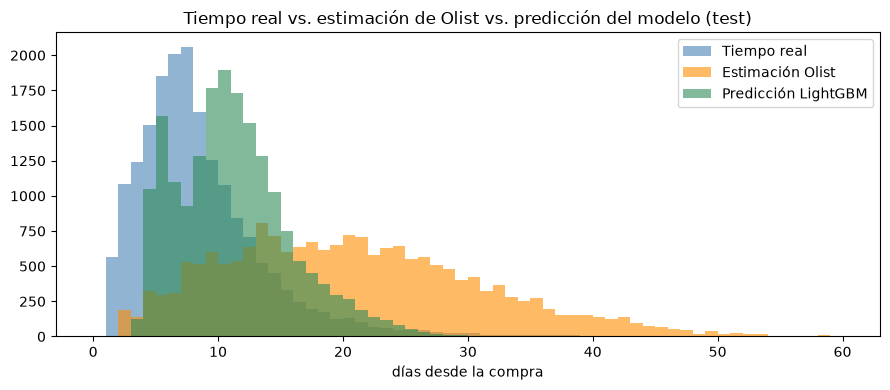

In [59]:
mae_olist = comparacion.loc["Estimación Olist", "MAE"]
mae_modelo = comparacion.loc[mejor_modelo, "MAE"]

print(f"Tiempo real medio:              {y_test.mean():.2f} días")
print(f"Estimación Olist media:         {estimacion_olist.mean():.2f} días")
print(f"Predicción media del modelo:    {pred_test.mean():.2f} días")
print()
print(f"Pedidos entregados DESPUÉS de la estimación de Olist: {(y_test > estimacion_olist).mean():.1%}")
print(f"Pedidos entregados DESPUÉS de la predicción del modelo: {(y_test > pred_test).mean():.1%}")
print()
print(f"Reducción del MAE frente a la estimación de Olist: {1 - mae_modelo / mae_olist:.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 60, 61)  # el gráfico se limita a 60 días para que se vea bien
ax.hist(y_test, bins=bins, alpha=0.6, label="Tiempo real", color="steelblue")
ax.hist(estimacion_olist, bins=bins, alpha=0.6, label="Estimación Olist", color="darkorange")
ax.hist(pred_test, bins=bins, alpha=0.6, label=f"Predicción {mejor_modelo}", color="seagreen")
ax.set_title("Tiempo real vs. estimación de Olist vs. predicción del modelo (test)")
ax.set_xlabel("días desde la compra")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/lead_time_comparacion_olist.png", bbox_inches="tight")
plt.show()

#### Extra (opcional): ¿qué fecha podría prometer el modelo?

La estimación de Olist es una *promesa* y no un pronóstico: está pensada para que pocos pedidos lleguen tarde. Para comparar de forma justa, se calcula cuánto margen de seguridad habría que sumar a la predicción del modelo para tener **la misma tasa de pedidos tardíos** que Olist, y cuántos días más cortos serían las promesas.

*Nota:* el margen se calcula con los propios datos de prueba, así que el resultado es orientativo. En producción habría que calibrarlo con un período de validación aparte.

In [60]:
# misma puntualidad que Olist: se suma al pronóstico un margen de seguridad
tasa_tarde_olist = (y_test > estimacion_olist).mean()
margen = np.quantile(y_test - pred_test, 1 - tasa_tarde_olist)
promesa_modelo = pred_test + margen

print(f"Tasa de pedidos tardíos de Olist: {tasa_tarde_olist:.1%}")
print(f"Margen de seguridad necesario:    {margen:.2f} días")
print(f"Promesa media con el modelo:      {promesa_modelo.mean():.2f} días")
print(f"Promesa media de Olist:           {estimacion_olist.mean():.2f} días")
print(f"Tasa de tardíos con el modelo:    {(y_test > promesa_modelo).mean():.1%}")
print(f"El modelo permitiría prometer en promedio {estimacion_olist.mean() - promesa_modelo.mean():.1f} días antes")

Tasa de pedidos tardíos de Olist: 5.5%
Margen de seguridad necesario:    4.76 días
Promesa media con el modelo:      15.97 días
Promesa media de Olist:           20.80 días
Tasa de tardíos con el modelo:    5.5%
El modelo permitiría prometer en promedio 4.8 días antes


### Conclusiones de la sección 9

- **Residuos:** el sesgo medio del modelo es de −2,59 días (mediana −3,05 días): LightGBM sobreestima el tiempo de entrega en el 80,6 % de los pedidos. Esto coincide con la diferencia entre la predicción media (11,21 días) y el tiempo real medio de test (8,63 días), y se explica por el cambio de distribución visto en la sección 8: el modelo aprendió de un período con entregas más lentas. Los residuos se concentran alrededor de −3 con una cola derecha larga (pedidos muy demorados que el modelo no anticipa, con residuos de hasta unos 60 días). En el gráfico de residuos vs. predicción se ve que, a mayor tiempo predicho, los residuos son más negativos: el modelo tiende a sobreestimar más los pedidos que cree lentos. El borde diagonal inferior del gráfico es esperable, porque `y` es siempre positivo y el residuo no puede ser menor que −ŷ.
- **Importancia de características:** las 10 variables principales concentran el 90 % de la ganancia total. Las tres más importantes son geográficas: `mismo_estado` (17,2 %), `customer_state` (16,5 %) y `distancia_km` (16,1 %), que juntas suman casi la mitad (49,8 %). Les siguen `mes` (10,5 %), `flete_total` (6,3 %), `volumen_dm3` (5,2 %), `product_category_name` (5,1 %), `peso_g` (4,7 %), `precio_total` (4,4 %) y `ratio_flete_precio` (4,1 %). La hora y el día de la semana no aparecen entre las 10 principales. La importancia de `mes` probablemente refleja el cambio de nivel del tiempo de entrega a lo largo del período y no una estacionalidad real, pero con este análisis no se puede confirmar.
- **Comparación con la estimación de Olist:** la estimación estática de Olist tiene MAE = 12,71 días, RMSE = 15,41 y R² = −6,20, frente a MAE = 4,30, RMSE = 5,68 y R² = 0,022 del modelo: una reducción del MAE del 66,2 %. La estimación media de Olist es de 20,80 días, mientras que el tiempo real medio en test es de 8,63 días: la plataforma promete en promedio 2,4 veces más de lo que tarda en realidad. Hay que tener en cuenta que no es una comparación entre dos pronósticos equivalentes: la estimación de Olist es una promesa deliberadamente conservadora, y las métricas de error reflejan sobre todo ese margen de seguridad.
- **Puntualidad:** solo el 5,5 % de los pedidos llega después de la estimación de Olist, y el 19,4 % llega después de la predicción cruda del modelo (por eso la predicción sola no puede usarse como promesa al cliente).
- **Extra (promesa calibrada):** sumando un margen de seguridad de 4,76 días a la predicción, el modelo mantiene la misma tasa de pedidos tardíos que Olist (5,5 %) con una promesa media de 15,97 días frente a 20,80: permitiría prometer en promedio 4,8 días antes. El margen se calculó con los datos de prueba, por lo que el resultado es orientativo y en producción la mejora sería algo menor.
- **Conclusión de negocio:** mostrar al cliente una fecha más cercana a la realidad mejoraría su experiencia sin aumentar los retrasos, y el modelo puede servir además para la planificación logística. Para usarlo como promesa haría falta calibrar el margen con un período de validación independiente.
- **Limitaciones:** el R² es bajo (0,022): las variables disponibles al momento de la compra permiten reducir el error promedio, pero no predecir bien qué pedidos se demorarán. El período de prueba tiene un nivel de tiempos de entrega distinto del de entrenamiento, lo que genera el sesgo de sobreestimación, y el dataset solo incluye pedidos ya entregados. Faltan variables externas (clima, huelgas, capacidad del transportista). Como mejora futura, se podría reentrenar el modelo periódicamente con ventanas recientes de datos y corregir el sesgo con un período de validación.

### Выводы к разделу 9

- **Остатки:** среднее смещение модели −2,59 дня (медиана −3,05): LightGBM завышает срок доставки у 80,6 % заказов. Это совпадает с разницей между средним предсказанием (11,21 дня) и реальным средним в тесте (8,63 дня) и объясняется сдвигом распределения из раздела 8: модель училась на периоде с более медленной доставкой. Остатки сосредоточены около −3 с длинным правым хвостом (очень долгие заказы, которые модель не предвидит, остатки до примерно 60 дней). На графике «остатки против прогноза» видно, что чем больше предсказанный срок, тем более отрицательны остатки: модель сильнее завышает сроки для заказов, которые считает медленными. Диагональная нижняя граница ожидаема: `y` всегда положительна, поэтому остаток не может быть меньше −ŷ.
- **Важность признаков:** 10 главных признаков дают 90 % общей важности. Первые три географические: `mismo_estado` (17,2 %), `customer_state` (16,5 %) и `distancia_km` (16,1 %), вместе почти половина (49,8 %). Далее `mes` (10,5 %), `flete_total` (6,3 %), `volumen_dm3` (5,2 %), `product_category_name` (5,1 %), `peso_g` (4,7 %), `precio_total` (4,4 %) и `ratio_flete_precio` (4,1 %). Час и день недели в первую десятку не вошли. Важность `mes`, вероятно, отражает смену уровня доставки во времени, а не настоящую сезонность, но этим анализом подтвердить нельзя.
- **Сравнение с оценкой Olist:** у статической оценки Olist MAE = 12,71 дня, RMSE = 15,41, R² = −6,20, у модели MAE = 4,30, RMSE = 5,68, R² = 0,022: MAE ниже на 66,2 %. Среднее обещание Olist 20,80 дня при реальном среднем 8,63: платформа обещает в среднем в 2,4 раза дольше фактического срока. Это сравнение не двух равноценных прогнозов: оценка Olist — намеренно консервативное обещание, и ошибки отражают в первую очередь этот запас.
- **Пунктуальность:** после оценки Olist приходит только 5,5 % заказов, а после «сырого» предсказания модели — 19,4 % (поэтому одно предсказание нельзя использовать как обещание клиенту).
- **Extra (откалиброванное обещание):** если добавить к предсказанию запас 4,76 дня, модель сохраняет ту же долю опозданий, что и Olist (5,5 %), при среднем обещании 15,97 дня против 20,80: можно обещать в среднем на 4,8 дня раньше. Запас считался по тестовым данным, поэтому результат ориентировочный, в реальной работе выигрыш был бы немного меньше.
- **Вывод для бизнеса:** показывать клиенту дату, более близкую к реальной, улучшило бы его опыт без роста опозданий, а модель полезна и для планирования логистики. Чтобы использовать её как обещание, нужно откалибровать запас на независимом валидационном периоде.
- **Ограничения:** низкий R² (0,022): признаки, известные в момент покупки, снижают среднюю ошибку, но плохо предсказывают, какие заказы задержатся. Тестовый период отличается по уровню сроков от обучающего, отсюда смещение с завышением, а в датасете только уже доставленные заказы. Нет внешних данных (погода, забастовки, мощности перевозчика). Улучшения: периодически переобучать модель на свежих данных и корректировать смещение по валидационному периоду.